# Práctica de detección de objetos

### De: Lucas Amado Oseira y María Lestón Geada


##### **Dataset:** Lettuce Pallets
##### **Moldelos:** Cascade R-CNN (Detectron2) y SSD300-VGG16 (Torchvision)


In [47]:
from google.colab import drive
import tarfile, random, torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

from PIL import Image

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

from torch.utils.data import Dataset, DataLoader
import torchvision

In [48]:
SEED = 2710

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


In [49]:
drive.mount('/content/drive')

DATA_ARCHIVE =  "/content/drive/MyDrive/dataset.tar.gz"
DATA_ROOT = Path("dataset")

DATA_ROOT.mkdir(exist_ok=True)

if not any(DATA_ROOT.iterdir()):
    with tarfile.open(DATA_ARCHIVE, "r:gz") as tar:
        tar.extractall(DATA_ROOT)

print(f"Dataset extracted to: {DATA_ROOT}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset extracted to: dataset


In [50]:
json_files = list(DATA_ROOT.glob("**/*.json"))
print(f"JSON encontrados: {len(json_files)}")
for path in json_files:
    print(f" - {path.relative_to(DATA_ROOT)}")

def split_token(path):
    s = str(path).lower()
    if "train" in s: return "train"
    elif "val" in s or "valid" in s: return "val"
    elif "test" in s: return "test"
    return None

ANN_FILES = {}

for split in ["train", "val", "test"]:
    candidates = [ p for p in json_files if split_token(p) == split]
    if candidates:
        ANN_FILES[split] = candidates[0]
        print(f"{split}: {ANN_FILES[split].relative_to(DATA_ROOT)}")

IMAGE_DIRS = {}
for split in ["train", "val", "test"]:
    candidates = [ p for p in DATA_ROOT.glob("**/*") if p.is_dir() and split_token(p) == split]
    if candidates:
        IMAGE_DIRS[split] = candidates[0]
        print(f"{split}: {IMAGE_DIRS[split].relative_to(DATA_ROOT)}")

print("ANN_FILES:", ANN_FILES)
print("IMAGE_DIRS:", IMAGE_DIRS)


JSON encontrados: 3
 - home/zuppif/Documents/Work/RoboFlow/ODinW-RF100-challenge/rf100/lettuce-pallets/train/_annotations.coco.json
 - home/zuppif/Documents/Work/RoboFlow/ODinW-RF100-challenge/rf100/lettuce-pallets/valid/_annotations.coco.json
 - home/zuppif/Documents/Work/RoboFlow/ODinW-RF100-challenge/rf100/lettuce-pallets/test/_annotations.coco.json
train: home/zuppif/Documents/Work/RoboFlow/ODinW-RF100-challenge/rf100/lettuce-pallets/train/_annotations.coco.json
val: home/zuppif/Documents/Work/RoboFlow/ODinW-RF100-challenge/rf100/lettuce-pallets/valid/_annotations.coco.json
test: home/zuppif/Documents/Work/RoboFlow/ODinW-RF100-challenge/rf100/lettuce-pallets/test/_annotations.coco.json
train: home/zuppif/Documents/Work/RoboFlow/ODinW-RF100-challenge/rf100/lettuce-pallets/train
val: home/zuppif/Documents/Work/RoboFlow/ODinW-RF100-challenge/rf100/lettuce-pallets/valid
test: home/zuppif/Documents/Work/RoboFlow/ODinW-RF100-challenge/rf100/lettuce-pallets/test
ANN_FILES: {'train': Posix

In [51]:
coco_train = COCO(str(ANN_FILES["train"]))
cats = sorted(coco_train.loadCats(coco_train.getCatIds()), key=lambda x: x["id"])
print(f"Categorías COCO: ", [(c["id"], c["name"]) for c in cats])
print(f"Total imágenes de entrenamiento: {len(coco_train.getImgIds())}")
print(f"Número de anotaciones train: {len(coco_train.getAnnIds())}")

CLASS_NAMES = [ c["name"] for c in cats ]
CLASS_IDS = [ c["id"] for c in cats ]
NUM_CLASSES = len(CLASS_NAMES)

loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
Categorías COCO:  [(0, 'lettuce'), (1, 'Ready'), (2, 'empty_pod'), (3, 'germination'), (4, 'pod'), (5, 'young')]
Total imágenes de entrenamiento: 1060
Número de anotaciones train: 13812


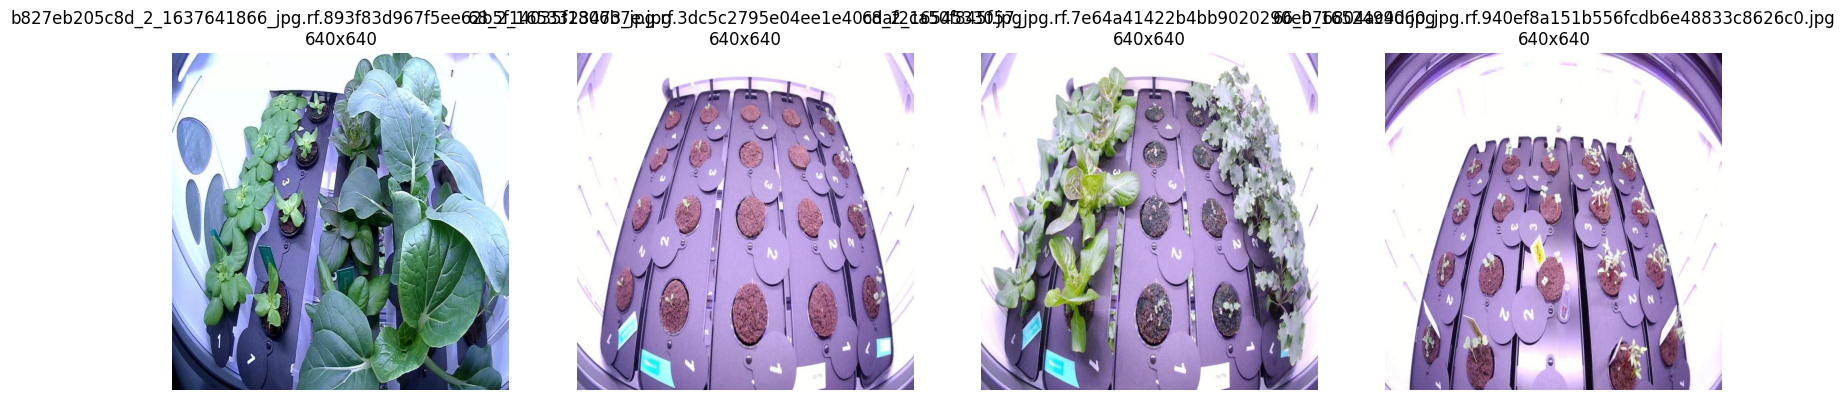

In [52]:
def show_coco(coco, image_dir, n=4):
    ids = random.sample(coco.getImgIds(), min(n, len(coco.getImgIds())))
    fig, axs = plt.subplots(1, len(ids), figsize=(5*len(ids), 5))
    if len(ids) == 1:
        axs = [axs]
    for ax, img_id in zip(axs, ids):
        img_info = coco.loadImgs(img_id)[0]
        img_path = image_dir / img_info["file_name"]
        img = plt.imread(img_path)
        ax.imshow(img)
        ax.set_title(f"{img_info['file_name']}\n{img_info['width']}x{img_info['height']}")
        ax.axis("off")
    plt.show()

show_coco(coco_train, IMAGE_DIRS["train"], n=4)

In [53]:
class CocoDetection(Dataset):
    def __init__(self, ann_file, image_dir, train=False):
        self.coco = COCO(str(ann_file))
        self.image_dir = Path(image_dir)
        self.ids = list(sorted(self.coco.getImgIds()))
        self.train = train

    def __len__(self):
        return len(self.ids)

    def _image_path(self, file_name):
        p = self.image_dir / file_name
        if p.exists():
            return p
        else:
            raise FileNotFoundError(f"Image file not found: {p}")

    def __getitem__(self, index):
        img_id = self.ids[index]
        img_info = self.coco.loadImgs(img_id)[0]
        image = Image.open(self._image_path(img_info["file_name"])).convert("RGB")

        ann_ids = self.coco.getAnnIds(imgIds=img_id)
        anns = self.coco.loadAnns(ann_ids)

        boxes = []
        labels = []

        for ann in anns:
            x, y, w, h = ann["bbox"]
            boxes.append([x, y, x + w, y + h])
            labels.append(ann["category_id"])

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([img_id]),
        }

        if self.train:
            # Apply any data augmentation here if needed
            pass

        return image, target

def collate_fn(batch):
    return tuple(zip(*batch))


train_ds = CocoDetection(ANN_FILES["train"], IMAGE_DIRS["train"], train=True)
val_ds = CocoDetection(ANN_FILES["val"], IMAGE_DIRS["val"], train=False)
test_ds = CocoDetection(ANN_FILES["test"], IMAGE_DIRS["test"], train=False)
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_ds, batch_size=4, shuffle=False, collate_fn=collate_fn)

        

loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


In [54]:
from torchvision.models.detection import ssd300_vgg16
from torchvision.models.detection import SSD300_VGG16_Weights
from torchvision.models.detection.ssd import SSDClassificationHead

def build_ssd(pretrained=True):
    weights = SSD300_VGG16_Weights.COCO_V1 if pretrained else None
    model = ssd300_vgg16(weights=weights)

    # Obtener los canales de entrada de cada capa directamente
    old_head = model.head.classification_head
    in_channels = [
        layer.in_channels for layer in old_head.module_list
    ]

    # Número de anchors por cada nivel de características
    num_anchors = model.anchor_generator.num_anchors_per_location()

    # Sustituir cabeza de clasificación para nuestras clases
    model.head.classification_head = SSDClassificationHead(
        in_channels=in_channels,
        num_anchors=num_anchors,
        num_classes=NUM_CLASSES + 1  # +1 para fondo
    )

    return model

ssd = build_ssd(pretrained=True).to(DEVICE)

print("SSD300 preparado correctamente.")

SSD300 preparado correctamente.


In [55]:
def train_one_epoch(model, loader, optimizer, device):
    model.train(); losses=[]
    for images, targets in loader:
        images = [im.to(device) for im in images]
        targets = [{k:v.to(device) for k,v in t.items()} for t in targets]
        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())
        optimizer.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        optimizer.step()
        losses.append(float(loss.detach().cpu()))
    return float(np.mean(losses))

@torch.no_grad()
def mean_detection_loss(model, loader, device):
    # Torchvision calcula loss solo en modo train; no actualizar gradientes.
    model.train(); vals=[]
    for images, targets in loader:
        images=[im.to(device) for im in images]
        targets=[{k:v.to(device) for k,v in t.items()} for t in targets]
        ld=model(images,targets); vals.append(float(sum(ld.values()).cpu()))
    model.eval()
    return float(np.mean(vals))

EPOCHS_SSD = 15
optimizer = torch.optim.SGD([p for p in ssd.parameters() if p.requires_grad],
                            lr=0.002, momentum=0.9, weight_decay=0.0005)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
history_ssd=[]
best_val=float("inf")
for epoch in range(EPOCHS_SSD):
    tr=train_one_epoch(ssd,train_loader,optimizer,DEVICE)
    vl=mean_detection_loss(ssd,val_loader,DEVICE)
    scheduler.step()
    history_ssd.append({"epoch":epoch+1,"train_loss":tr,"val_loss":vl})
    print(f"SSD epoch {epoch+1}/{EPOCHS_SSD}: train={tr:.4f} val={vl:.4f}")
    if vl < best_val:
        best_val=vl
        torch.save(ssd.state_dict(),"ssd300_baseline_best.pth")
ssd.load_state_dict(torch.load("ssd300_baseline_best.pth",map_location=DEVICE))
ssd.eval()
pd.DataFrame(history_ssd).plot(x="epoch",y=["train_loss","val_loss"],grid=True,title="SSD300 baseline")
plt.show()

AttributeError: 'Image' object has no attribute 'to'

In [ ]:
# Esta celda requiere detectron2 instalado correctamente.
from detectron2.data.datasets import register_coco_instances
from detectron2.data import MetadataCatalog, DatasetCatalog
from detectron2.engine import DefaultTrainer, DefaultPredictor
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader

for split in ("train","val","test"):
    if split in ANN_FILES and split in IMAGE_DIRS:
        name=f"lettuce_{split}"
        if name in DatasetCatalog.list(): DatasetCatalog.remove(name)
        register_coco_instances(name, {}, str(ANN_FILES[split]), str(IMAGE_DIRS[split]))
        MetadataCatalog.get(name).set(thing_classes=CLASS_NAMES)

CASCADE_CONFIG = "Misc/cascade_mask_rcnn_R_50_FPN_3x.yaml"
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(CASCADE_CONFIG))
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CASCADE_CONFIG)
cfg.MODEL.MASK_ON = False
cfg.DATASETS.TRAIN = ("lettuce_train",)
cfg.DATASETS.TEST = ("lettuce_val",)
cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.ROI_HEADS.NUM_CLASSES = NUM_CLASSES
cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.00025
cfg.SOLVER.MAX_ITER = max(500, len(train_ds)//2 * 10)
cfg.SOLVER.STEPS = (int(cfg.SOLVER.MAX_ITER*0.7), int(cfg.SOLVER.MAX_ITER*0.9))
cfg.SOLVER.CHECKPOINT_PERIOD = max(100, cfg.SOLVER.MAX_ITER//3)
cfg.TEST.EVAL_PERIOD = max(100, cfg.SOLVER.MAX_ITER//5)
cfg.OUTPUT_DIR = "./output_cascade_baseline"
os.makedirs(cfg.OUTPUT_DIR,exist_ok=True)
# Evita sobrescribir configuración con valores previos del entorno.
trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

In [ ]:
def evaluate_detectron2(cfg, split="val"):
    evaluator = COCOEvaluator(f"lettuce_{split}", output_dir=cfg.OUTPUT_DIR)
    loader = build_detection_test_loader(cfg, f"lettuce_{split}")
    return inference_on_dataset(DefaultPredictor(cfg).model, loader, evaluator)

# Si el entrenamiento ha terminado, cargar el último/best checkpoint.
cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")
cascade_results = evaluate_detectron2(cfg, "val")
print(cascade_results)

In [ ]:
@torch.no_grad()
def torchvision_predictions_to_coco(model, dataset, score_thresh=0.001):
    model.eval(); predictions=[]
    loader=DataLoader(dataset,batch_size=2,shuffle=False,num_workers=2,collate_fn=collate_fn)
    for images, targets in loader:
        outputs=model([im.to(DEVICE) for im in images])
        for target,out in zip(targets,outputs):
            image_id=int(target["image_id"].item())
            for box,score,label in zip(out["boxes"].cpu(),out["scores"].cpu(),out["labels"].cpu()):
                if float(score)<score_thresh: continue
                x1,y1,x2,y2=map(float,box.tolist())
                contig=int(label)-1
                if contig<0 or contig>=NUM_CLASSES: continue
                predictions.append({"image_id":image_id,"category_id":cat_ids[contig],
                                    "bbox":[x1,y1,max(0,x2-x1),max(0,y2-y1)],
                                    "score":float(score)})
    return predictions

def coco_metrics(coco_gt, predictions):
    if not predictions:
        return {"mAP50":0.0,"mAP50_95":0.0}
    coco_dt=coco_gt.loadRes(predictions)
    ev=COCOeval(coco_gt,coco_dt,"bbox")
    ev.evaluate(); ev.accumulate(); ev.summarize()
    return {"mAP50_95":float(ev.stats[0]),"mAP50":float(ev.stats[1])}

coco_val=COCO(str(ANN_FILES["val"]))
ssd_val_preds=torchvision_predictions_to_coco(ssd,val_ds)
ssd_val_metrics=coco_metrics(coco_val,ssd_val_preds)
print("SSD300 validation:",ssd_val_metrics)